# 01 — Data Audit


In [2]:
%load_ext autoreload
%autoreload 2
import hashlib
import os
import sys

sys.path.append('..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import models, transforms
from tqdm import tqdm

from src.dataset import average_hash, get_embedding, md5_hash, scan_all_images

DATA_ROOT='../data/raw/dataset'
os.listdir(DATA_ROOT)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


['test', 'train', 'unclean']

In [3]:
os.listdir(os.path.join(DATA_ROOT , 'train'))

['ambulance',
 'autobus',
 'kamyun',
 'kamyunet',
 'minibus',
 'savari',
 'taxi',
 'vanet']

In [4]:

os.listdir(os.path.join(DATA_ROOT , 'unclean'))

['ambulance',
 'autobus',
 'kamyun',
 'kamyunet',
 'minibus',
 'neysan',
 'savari',
 'taxi',
 'vanet']

In [5]:
def count_classes(split_path):
    counts= {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join (split_path , class_name)
        if os.path.isdir(class_dir):
            counts[class_name] = len(os.listdir(class_dir))
    return counts

train_count = count_classes (os.path.join(DATA_ROOT , 'train'))
print(train_count)

{'ambulance': 219, 'autobus': 245, 'kamyun': 250, 'kamyunet': 238, 'minibus': 230, 'savari': 248, 'taxi': 249, 'vanet': 249}


In [6]:
def count_classes(split_path):
    counts= {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join (split_path , class_name)
        if os.path.isdir(class_dir):
            counts[class_name] = len(os.listdir(class_dir))
    return counts

unclean_count = count_classes (os.path.join(DATA_ROOT , 'unclean'))
print(unclean_count)

{'ambulance': 157, 'autobus': 226, 'kamyun': 246, 'kamyunet': 221, 'minibus': 185, 'neysan': 250, 'savari': 250, 'taxi': 243, 'vanet': 250}


In [7]:
train_classes = set (train_count.keys())
unclean_classes = set (unclean_count.keys())

print("train:" , train_classes - unclean_classes)
print("unclean:" , unclean_classes - train_classes)
print("both:" , train_classes & unclean_classes)


train: set()
unclean: {'neysan'}
both: {'kamyunet', 'vanet', 'autobus', 'minibus', 'taxi', 'kamyun', 'savari', 'ambulance'}


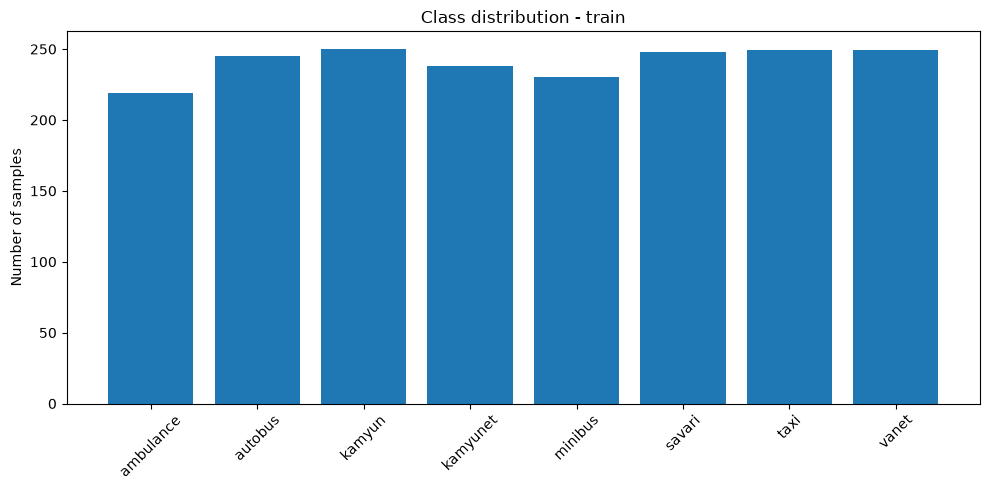

In [8]:
plt.figure(figsize=(10, 5))
plt.bar(train_count.keys(), train_count.values())
plt.xticks(rotation=45)
plt.title('Class distribution - train')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.show()


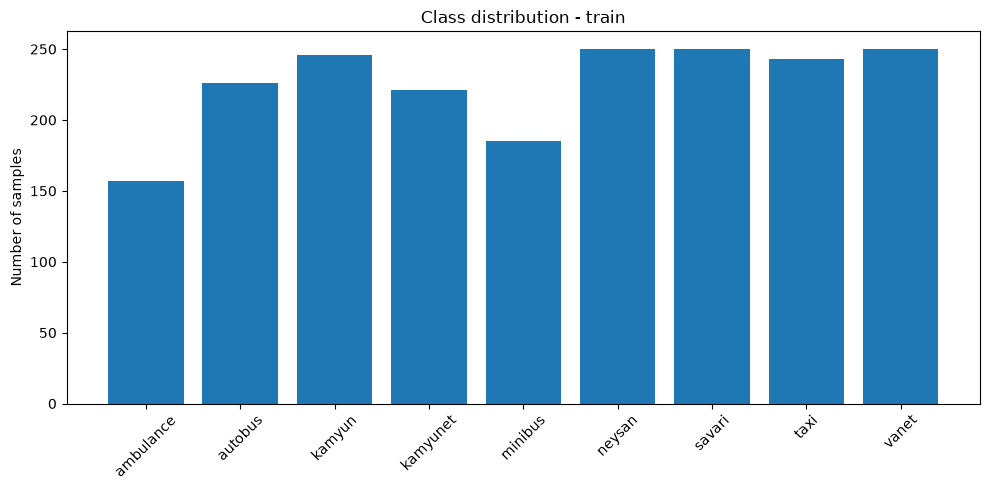

In [9]:
plt.figure(figsize=(10, 5))
plt.bar(unclean_count.keys(), unclean_count.values())
plt.xticks(rotation=45)
plt.title('Class distribution - train')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.show()

## MD5 & Average Hashing:

In [10]:
records = scan_all_images(DATA_ROOT)
df = pd.DataFrame(records)
print(f"All scanned photos:{len(df)}")

md5_dupes = df [df.duplicated(subset='md5' , keep=False)]. sort_values('md5')
print(f"Duplicate groups with md5 : {md5_dupes['md5'].nunique()}")

avghash_dupes=df[df.duplicated(subset='avghash' , keep=False)].sort_values('avghash')
print(f"Duplicate groups with avghash: {avghash_dupes['avghash'].nunique()}")

def check_label_conflicts(dupes_df , hash_col):
    conflict = []
    for h , group in dupes_df.groupby(hash_col):
        if group['class'].nunique()>1:
            conflict.append(group)
    return conflict

md5_conflicts = check_label_conflicts(md5_dupes , 'md5')
avghash_conflicts=check_label_conflicts(avghash_dupes , 'avghash')
print(f"\nGroups with label conflicts(md5) :{len(md5_conflicts)}")
print(f"\nGroups with label conflicts(avghash): {len(avghash_conflicts)}")


train_df = df[df['split'] == 'train'].copy()
print(f"length of train img {len(train_df)}")



hashing images: 100%|██████████| 4356/4356 [00:07<00:00, 600.40it/s]

All scanned photos:4356
Duplicate groups with md5 : 23
Duplicate groups with avghash: 45

Groups with label conflicts(md5) :0

Groups with label conflicts(avghash): 7
length of train img 1928


In [11]:
def rescan(data_root=DATA_ROOT):
    global df
    df = scan_all_images(data_root)
    print(f"🔄 Rescanned: {len(df)} images")
    return df


In [12]:
counts_by_split_class = df.groupby(['split', 'class']).size().reset_index(name='count')
print(counts_by_split_class.to_string())

print("\n--- جمع کل هر split ---")
print(df.groupby('split').size())

      split      class  count
0      test  ambulance     50
1      test    autobus     50
2      test     kamyun     50
3      test   kamyunet     50
4      test    minibus     50
5      test     savari     50
6      test       taxi     50
7      test      vanet     50
8     train  ambulance    219
9     train    autobus    245
10    train     kamyun    250
11    train   kamyunet    238
12    train    minibus    230
13    train     savari    248
14    train       taxi    249
15    train      vanet    249
16  unclean  ambulance    157
17  unclean    autobus    226
18  unclean     kamyun    246
19  unclean   kamyunet    221
20  unclean    minibus    185
21  unclean     neysan    250
22  unclean     savari    250
23  unclean       taxi    243
24  unclean      vanet    250

--- جمع کل هر split ---
split
test        400
train      1928
unclean    2028
dtype: int64



md5 conflict group :
No md5 conflicts found!

 average hash conflicts0
____________________


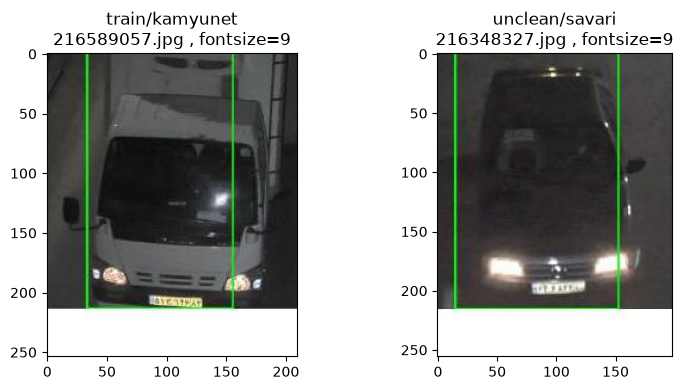


 average hash conflicts1
____________________


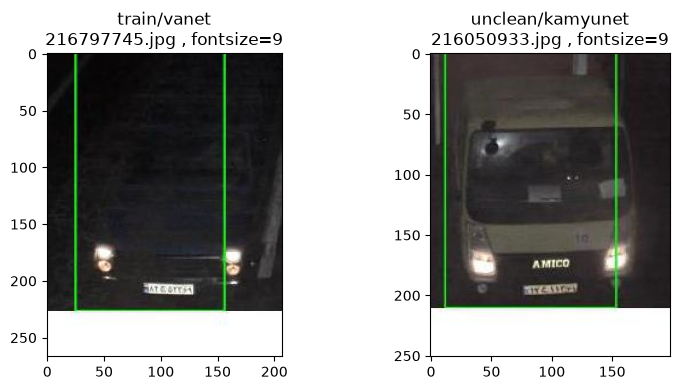


 average hash conflicts2
____________________


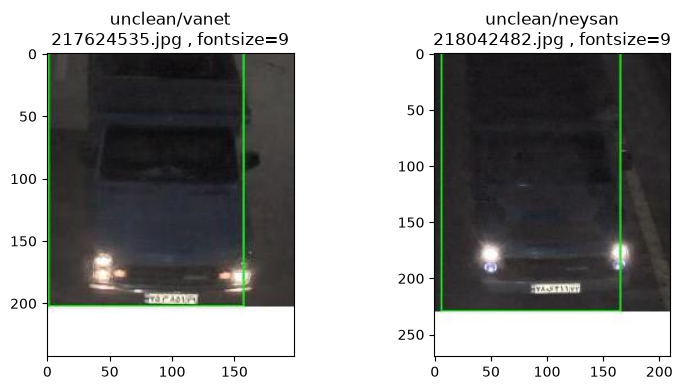


 average hash conflicts3
____________________


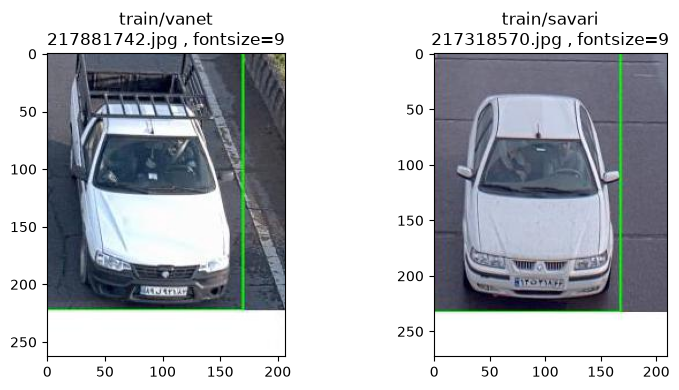


 average hash conflicts4
____________________


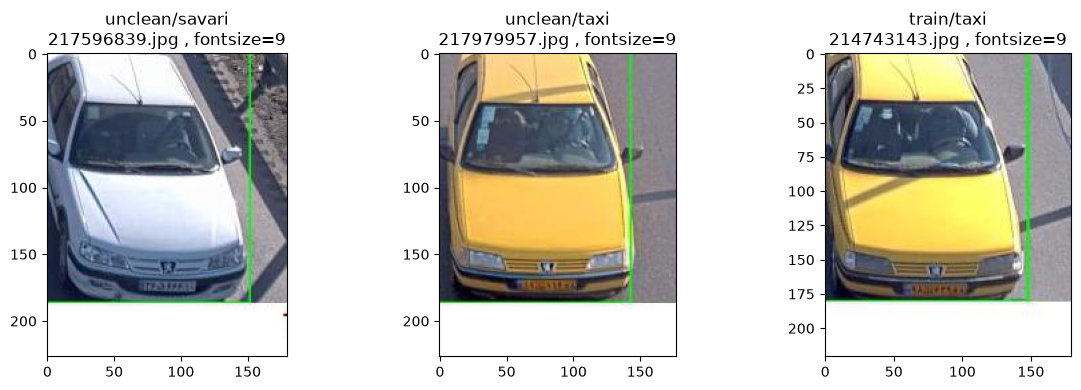


 average hash conflicts5
____________________


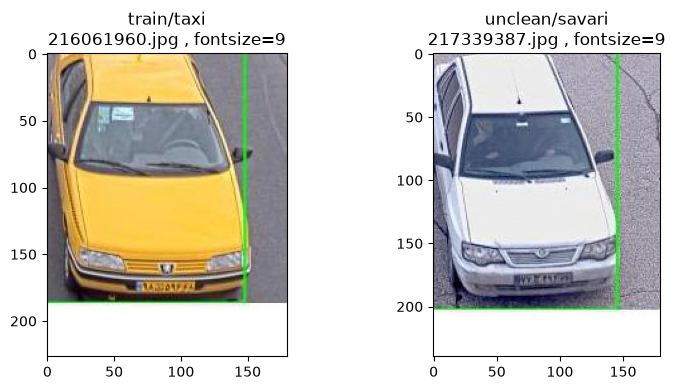


 average hash conflicts6
____________________


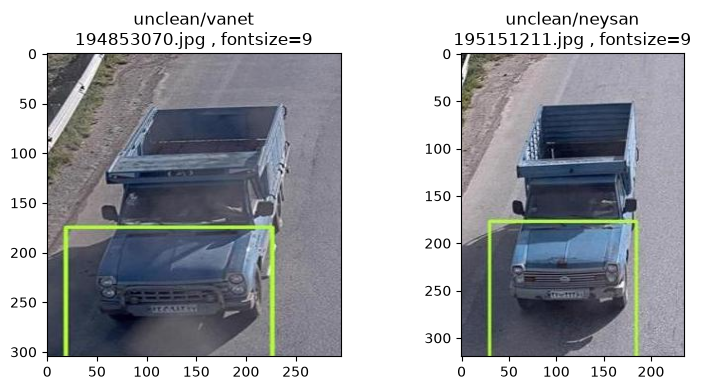

In [13]:
def show_conflict_group(conflict_groups , group_index=0):
    group = conflict_groups[group_index]
    n = len(group)
    fig , axes = plt.subplots(1 , n , figsize=(4*n , 4))
    if n == 1:
        axes = [axes]
    for ax , (_, row) in zip (axes, group.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"{row['split']}/{row['class']}\n{row['filename']} , fontsize=9")
    plt.tight_layout()
    plt.show()

print("\nmd5 conflict group :")
if md5_conflicts:
    show_conflict_group(md5_conflicts, group_index=0)
else:
    print("No md5 conflicts found!")

for i in range(len(avghash_conflicts)):
    print(f"\n average hash conflicts{i}")
    print("_" * 20)
    show_conflict_group(avghash_conflicts , group_index=i)

## Resnet18:

In [25]:
df = pd.DataFrame(scan_all_images(DATA_ROOT))
train_df = df[df['split'] == 'train'].copy().reset_index(drop=True)
print(f"train images: {len(train_df)}")


embeddings, valid_idx = [], []
for i, path in enumerate(tqdm(train_df['path'], desc="computing embeddings")):
    try:
        embeddings.append(get_embedding(path))
        valid_idx.append(i)
    except Exception as e:
        print(f"skipped {path}: {e}")

train_df = train_df.iloc[valid_idx].copy().reset_index(drop=True)
train_df['embedding'] = embeddings


train_df['centroid_distance'] = np.nan
for class_name, group in train_df.groupby('class'):
    class_embeddings = np.stack(group['embedding'].values)
    centroid = class_embeddings.mean(axis=0)
    train_df.loc[group.index, 'centroid_distance'] = np.linalg.norm(class_embeddings - centroid, axis=1)

suspects = (
    train_df.sort_values('centroid_distance', ascending=False)
    .groupby('class').head(15)
)



hashing images: 100%|██████████| 4352/4352 [00:06<00:00, 682.66it/s]


train images: 1924


computing embeddings: 100%|██████████| 1924/1924 [01:37<00:00, 19.77it/s]


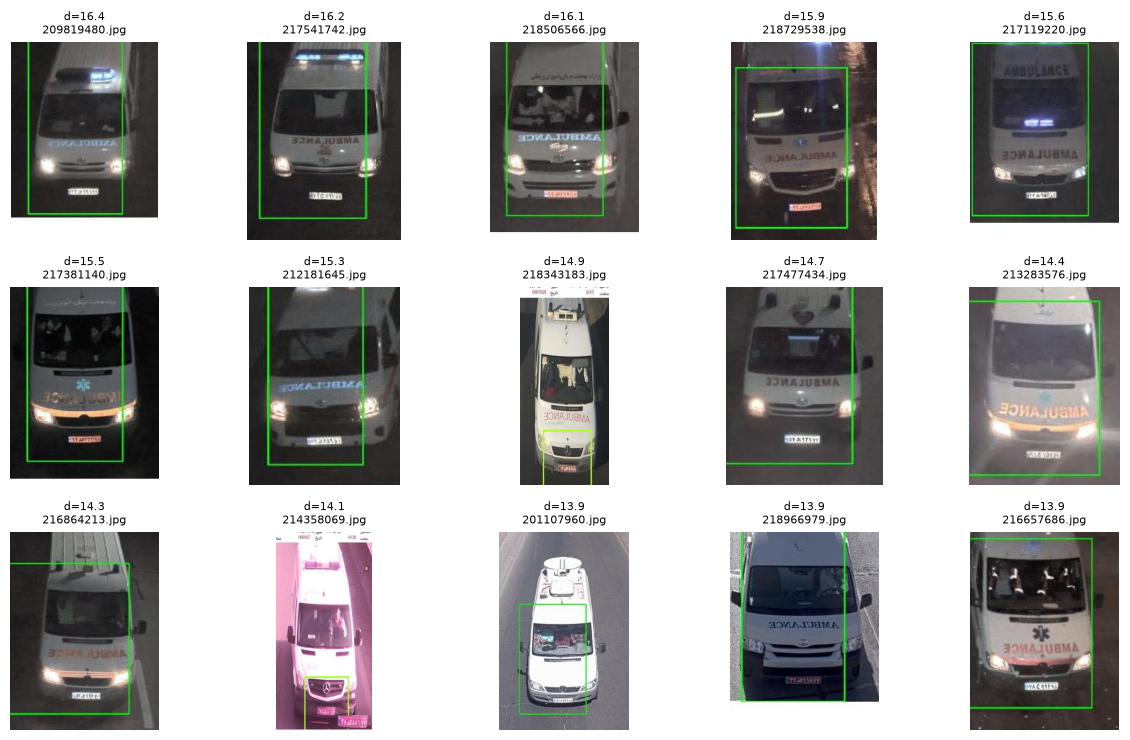

In [15]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'ambulance')

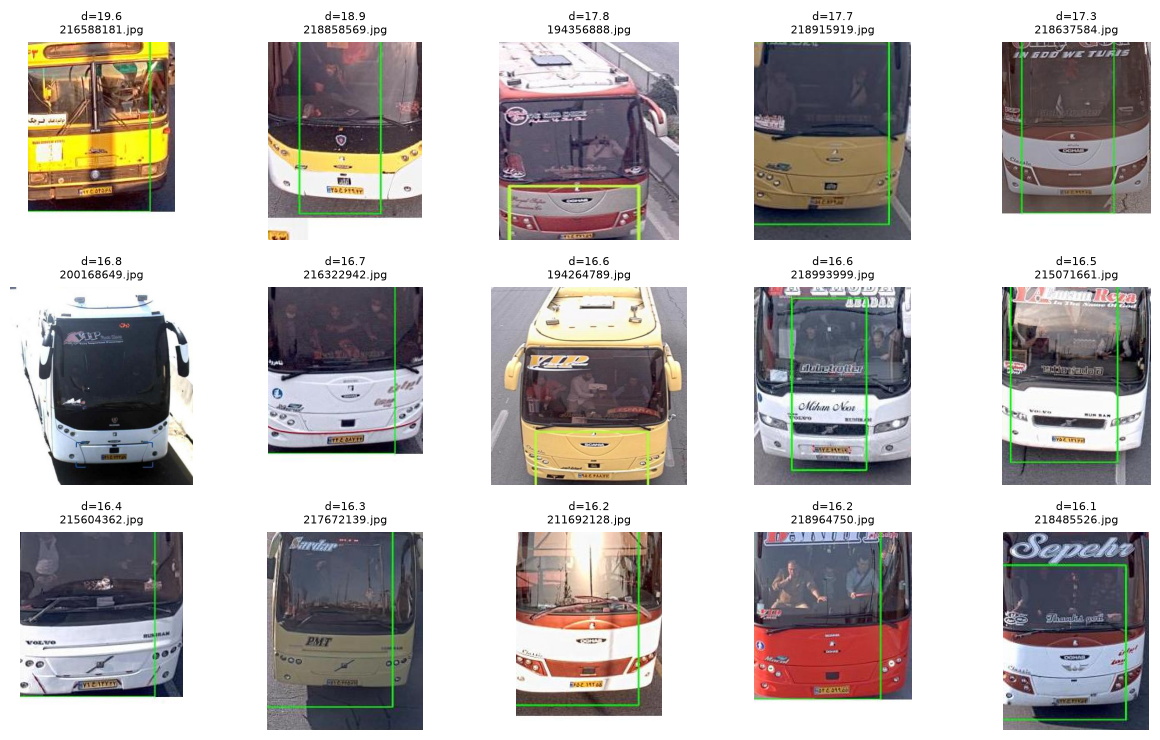

In [16]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'autobus')

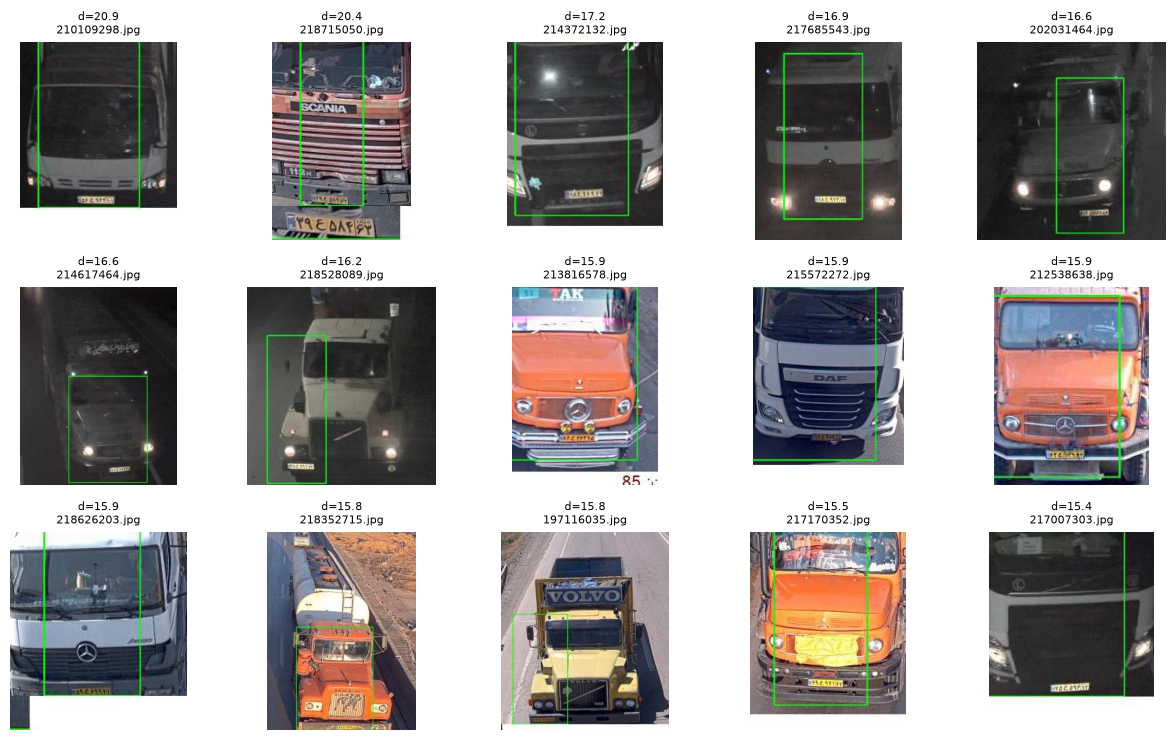

In [17]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'kamyun')

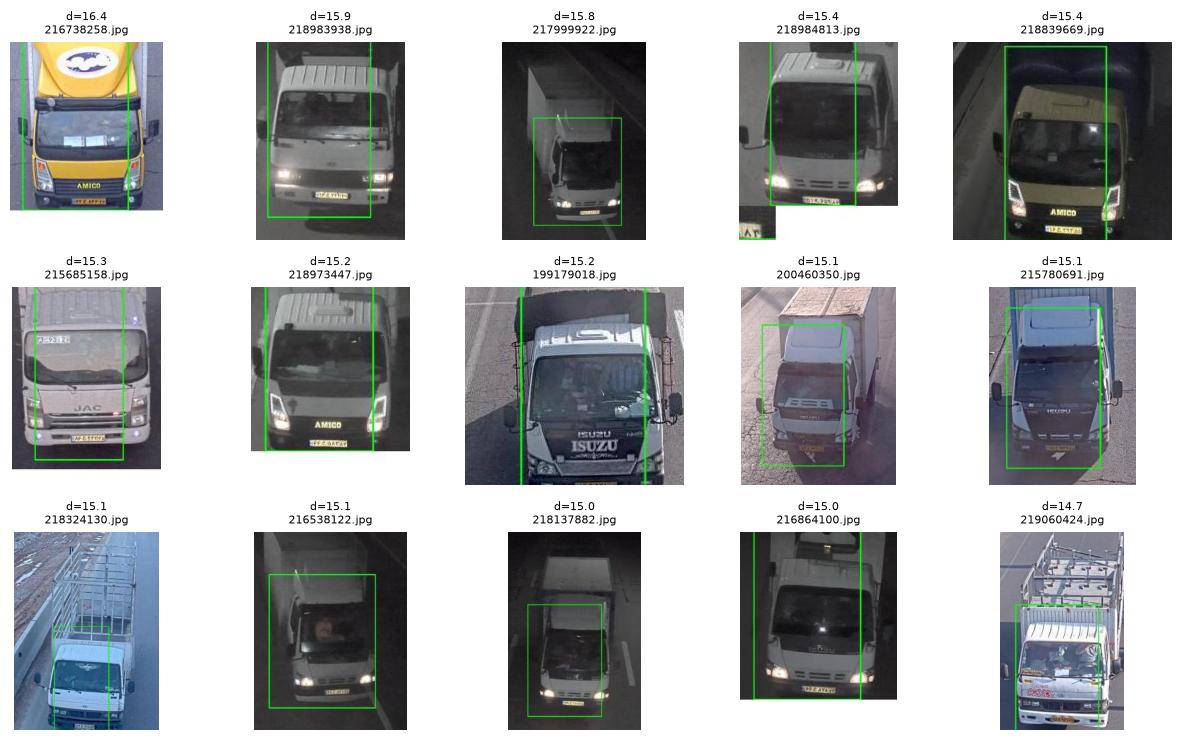

In [18]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'kamyunet')

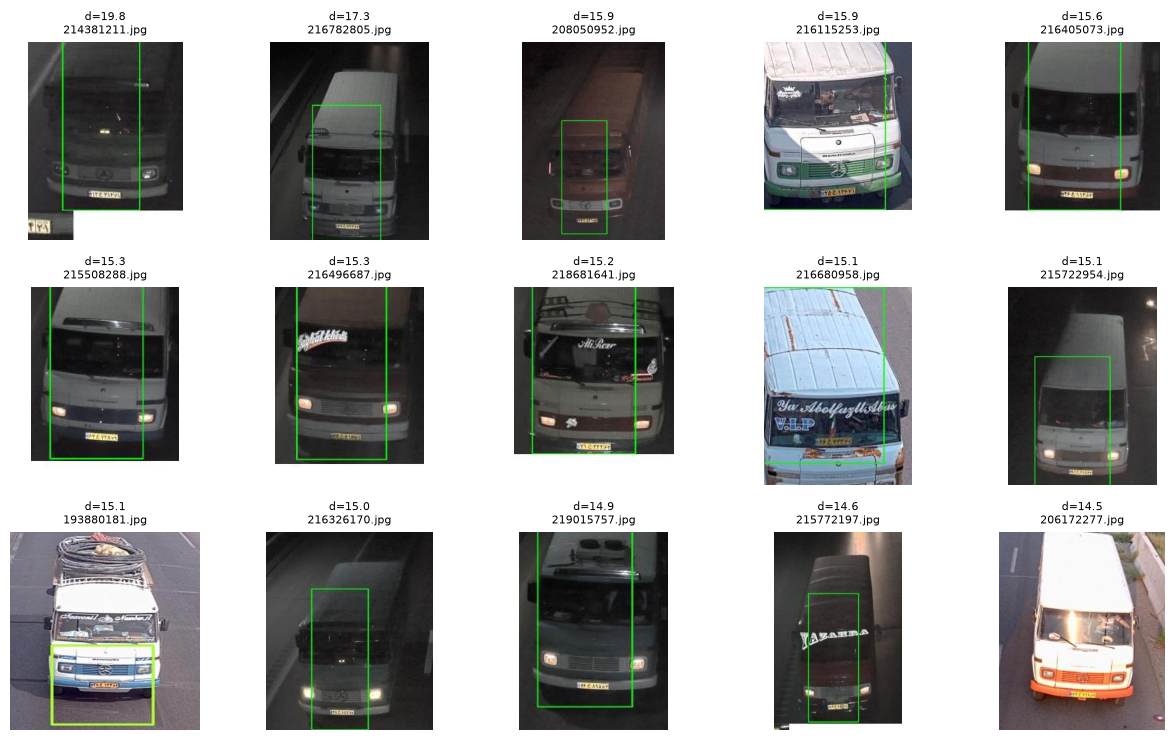

In [26]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'minibus')

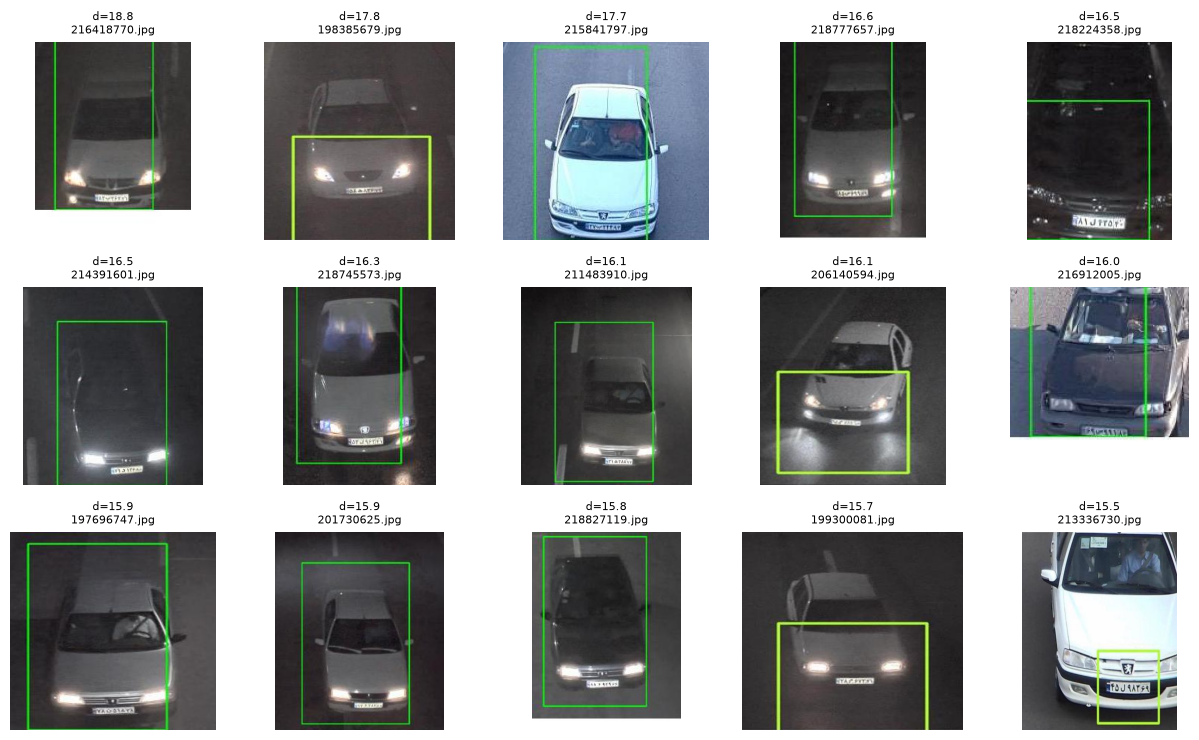

In [20]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'savari')

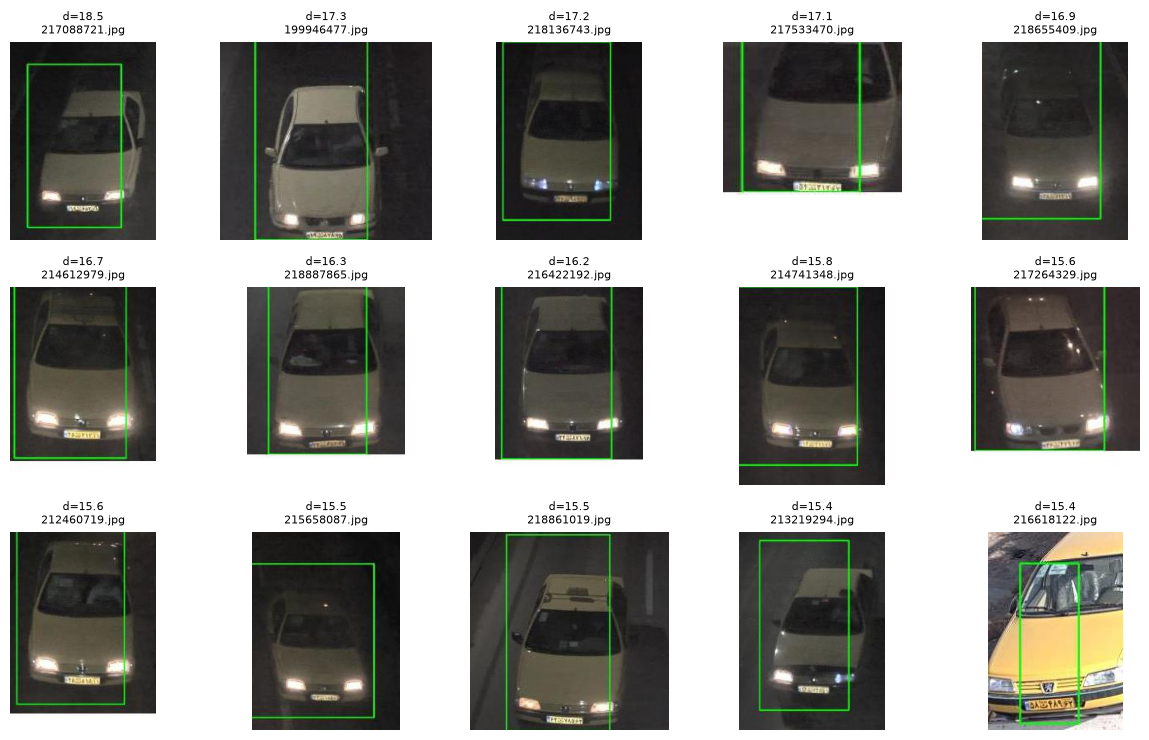

In [21]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'taxi')

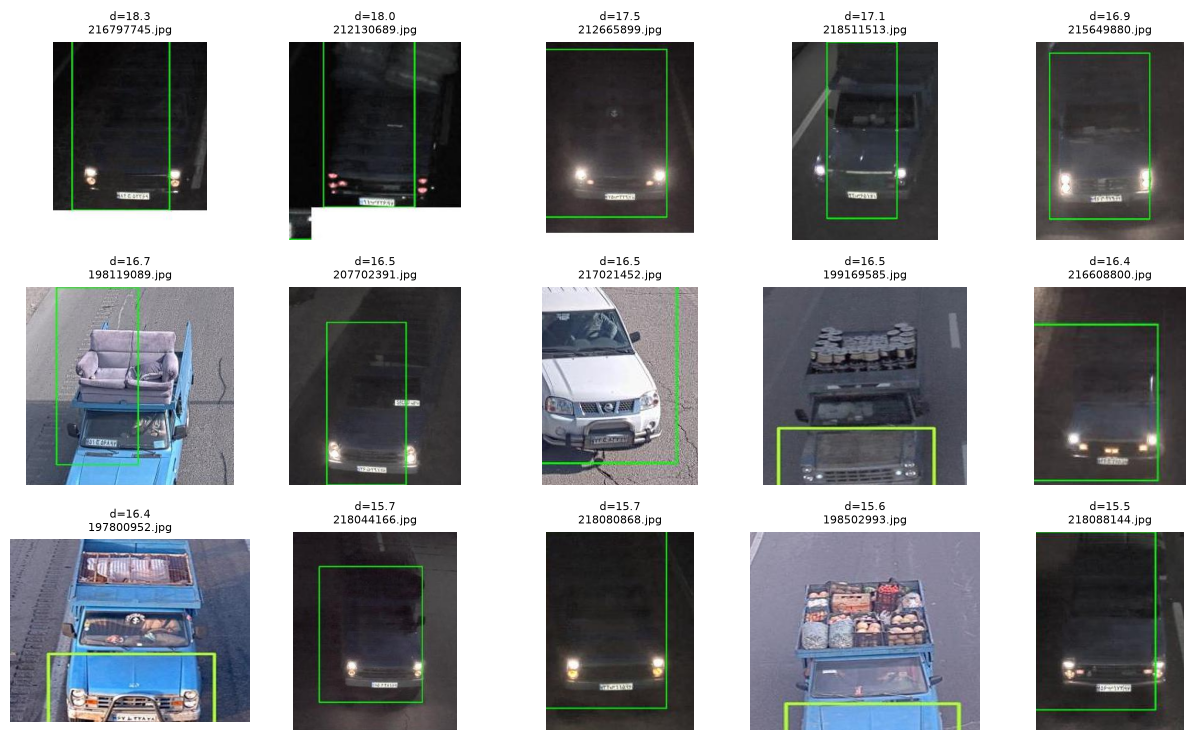

In [22]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'vanet')

## split:
